In [1]:
'''Apply exhaustive Grid Search hyperparameter optimization for machine learning algorithms, 
automating model tuning with cross-validation and parallel processing to identify the best-performing parameter sets.'''

'Apply exhaustive Grid Search hyperparameter optimization for machine learning algorithms, \nautomating model tuning with cross-validation and parallel processing to identify the best-performing parameter sets.'

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [3]:
df = pd.read_csv("global_pharmacy_sales_data.csv")

print("dataset shape:", df.shape)
display(df.head())

print("\nmissing values:")
print(df.isnull().sum())

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0



missing values:
date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64


In [4]:
# data preprocessing 
# remove duplicate records

df = df.drop_duplicates()

# remove unnecessary date column
df = df.drop(columns=["date"], errors="ignore")

# handle missing values
df = df.dropna(subset=["units_sold"])

# separate features and target

X = df.drop(columns=["units_sold"])
y = df["units_sold"]

# identify numerical and categorical columns

numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("numerical features:", numeric_features)
print("categorical features:", categorical_features)

print("\ntarget variable: units_sold")

numerical features: ['year', 'month', 'day', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
categorical features: ['region', 'country', 'category', 'medicine', 'age_group']

target variable: units_sold


In [5]:
# split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("training records:", X_train.shape[0])
print("testing records:", X_test.shape[0])

training records: 140288
testing records: 35072


In [6]:
# preprocess numerical and categorical features

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("feature preprocessing completed")

feature preprocessing completed


In [7]:
# define regression algorithms

models = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),

    "Extra Trees": ExtraTreesRegressor(
        random_state=42,
        n_jobs=1
    )
}

print("models selected for optimization:")

for name in models:
    print(name)

models selected for optimization:
Decision Tree
Random Forest
Extra Trees


In [8]:
# define parameter combinations for exhaustive grid search

parameter_grids = {
    "Decision Tree": {
        "model__max_depth": [10, 20, None],
        "model__min_samples_split": [2, 10]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [15, None]
    },

    "Extra Trees": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [15, None]
    }
}

print("hyperparameter grids:")

for name, params in parameter_grids.items():
    print("\n", name)
    for parameter, values in params.items():
        print(parameter, ":", values)

hyperparameter grids:

 Decision Tree
model__max_depth : [10, 20, None]
model__min_samples_split : [2, 10]

 Random Forest
model__n_estimators : [100, 200]
model__max_depth : [15, None]

 Extra Trees
model__n_estimators : [100, 200]
model__max_depth : [15, None]


In [9]:
# configure cross-validation

cv_strategy = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("cross-validation: 3-fold")
print("shuffling: enabled")
print("random state: 42")

cross-validation: 3-fold
shuffling: enabled
random state: 42


In [10]:
#Exhaustive Grid Search optimization
# use a representative training sample to reduce tuning time

tuning_size = min(30000, len(X_train))

X_tuning = X_train.sample(
    n=tuning_size,
    random_state=42
)

y_tuning = y_train.loc[X_tuning.index]

# store optimization results

grid_results = []
best_estimators = {}

# perform exhaustive grid search for each algorithm

for name, model in models.items():

    print("\noptimizing:", name)

    # create machine learning pipeline

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # configure exhaustive grid search

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grids[name],
        scoring="neg_root_mean_squared_error",
        cv=cv_strategy,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    # execute all parameter combinations

    grid_search.fit(X_tuning, y_tuning)

    # store the best estimator

    best_estimators[name] = grid_search.best_estimator_

    # store optimization results

    grid_results.append({
        "Model": name,
        "Best CV RMSE": -grid_search.best_score_,
        "Best Parameters": grid_search.best_params_,
        "Total Combinations": len(grid_search.cv_results_["params"])
    })

    print("best parameters:", grid_search.best_params_)
    print("best cross-validation RMSE:", -grid_search.best_score_)

print("\nall models optimized successfully")


optimizing: Decision Tree
Fitting 3 folds for each of 6 candidates, totalling 18 fits
best parameters: {'model__max_depth': 10, 'model__min_samples_split': 10}
best cross-validation RMSE: 88.66760236835034

optimizing: Random Forest
Fitting 3 folds for each of 4 candidates, totalling 12 fits
best parameters: {'model__max_depth': 15, 'model__n_estimators': 200}
best cross-validation RMSE: 83.35065787263572

optimizing: Extra Trees
Fitting 3 folds for each of 4 candidates, totalling 12 fits
best parameters: {'model__max_depth': 15, 'model__n_estimators': 200}
best cross-validation RMSE: 84.74680328842653

all models optimized successfully


In [11]:
#Compare optimized models
# create comparison dataframe

results_df = pd.DataFrame(grid_results)

# sort models by cross-validation RMSE

results_df = results_df.sort_values(
    by="Best CV RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df)

,Model,Best CV RMSE,Best Parameters,Total Combinations
0,Random Forest,83.350658,"{'model__max_depth': 15, 'model__n_estimators'...",4
1,Extra Trees,84.746803,"{'model__max_depth': 15, 'model__n_estimators'...",4
2,Decision Tree,88.667602,"{'model__max_depth': 10, 'model__min_samples_s...",6


In [12]:
#Select the best-performing model
# identify the best-performing algorithm

best_model_name = results_df.loc[0, "Model"]

best_parameters = results_df.loc[0, "Best Parameters"]

print("best algorithm:", best_model_name)

print("\nbest hyperparameters:")
print(best_parameters)

print("\nbest cross-validation RMSE:",
      round(results_df.loc[0, "Best CV RMSE"], 4))

best algorithm: Random Forest

best hyperparameters:
{'model__max_depth': 15, 'model__n_estimators': 200}

best cross-validation RMSE: 83.3507


In [13]:
#Retrain optimized model on complete training data
final_model = best_estimators[best_model_name]

# apply the selected parameters to the complete training dataset

final_model.set_params(**best_parameters)

final_model.fit(X_train, y_train)

print("best model retrained on complete training data")

best model retrained on complete training data


In [14]:
#Final model evaluation
# generate predictions on unseen testing data

y_pred = final_model.predict(X_test)

# calculate regression evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

# display final performance

evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R-Squared"],
    "Score": [mae, rmse, r2]
})

display(evaluation_results)

,Metric,Score
0,MAE,64.488044
1,RMSE,84.277765
2,R-Squared,0.939063


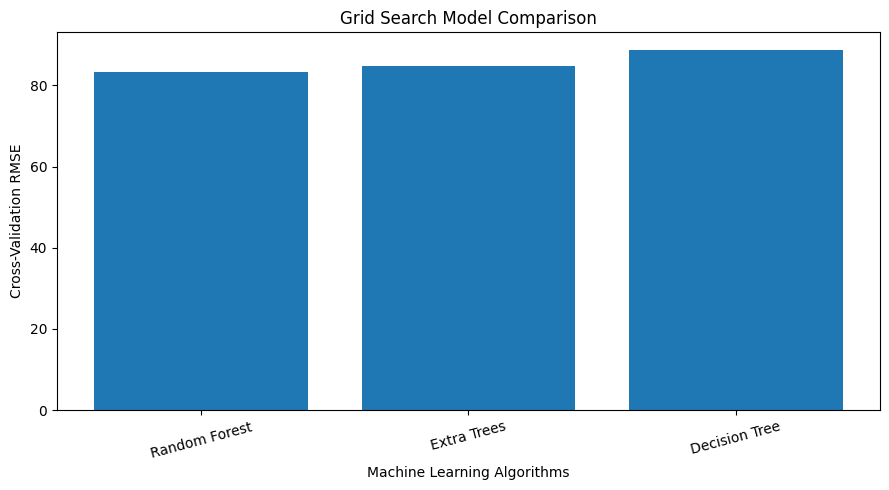

In [15]:
#Visualize model comparison
import matplotlib.pyplot as plt

# compare cross-validation rmse values

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Best CV RMSE"]
)

plt.title("Grid Search Model Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Cross-Validation RMSE")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

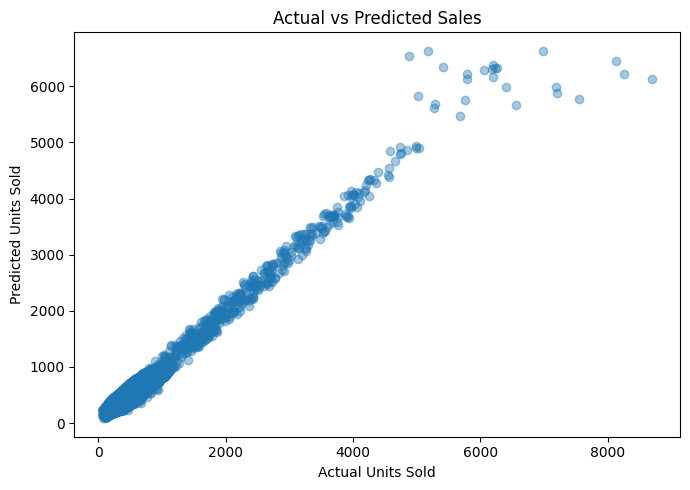

In [16]:
## compare actual and predicted sales units

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

plt.xlabel("Actual Units Sold")
plt.ylabel("Predicted Units Sold")
plt.title("Actual vs Predicted Sales")

plt.tight_layout()
plt.show()